# Modelado, evaluación y uso del modelo

**Proyecto:** anticipar qué divisiones de la industria manufacturera argentina van a estar en contracción interanual 3 meses después del momento de la predicción.
**Alumna:** Mónica Frías — Aprendizaje Automático, 2026.

Este notebook continúa a [`1.0-mf-carga-exploracion-dataset.ipynb`](1.0-mf-carga-exploracion-dataset.ipynb), que arma la tabla de modelado, trata los faltantes y explora las variables.

### El problema, en una tabla

| Pregunta | Respuesta |
|---|---|
| ¿Qué representa una fila? | Una división de la industria (16 en total) en un mes *t*. |
| ¿Qué se predice? | Si la división va a estar en **contracción interanual** en el mes *t+5*: producción de *t+5* menor que la del mismo mes del año anterior. Clase positiva: **1 = contracción**. |
| ¿Cuándo se predice? | En el mes *t+2*, cuando el INDEC publica el IPI del mes *t*. El mes predicho queda **3 meses después** y su resultado se conoce en *t+7*. |
| ¿Con qué información? | 15 predictoras publicadas antes de *t+2*: evolución reciente de la propia división, capacidad instalada (con un mes de rezago), tipo de cambio, tasa BADLAR y balanza comercial (ver [diccionario de datos](../docs/diccionario_de_datos.md)). |
| ¿Para qué? | Alerta temprana para empresas, cámaras sectoriales y organismos públicos: priorizar el seguimiento de las divisiones con más riesgo de caída. Un **falso negativo** es una contracción que no se anticipó; un **falso positivo**, una alerta que no se cumplió. |

### Diseño del experimento

1. **Separación temporal** (sin repartir un mes entre conjuntos): entrenamiento con las filas cuyo resultado se conocía antes de enero 2025 (datos de abril 2017 a mayo 2024); **evaluación final** con las predicciones hechas desde enero 2025 (datos de noviembre 2024 a marzo 2026); **pendientes** las filas cuyo resultado todavía no se publicó.
2. **Selección de hiperparámetros** solo dentro del entrenamiento, con **validación temporal** de 4 cortes (enero 2021, 2022, 2023 y 2024). El escalado está dentro del pipeline, así que se ajusta con el entrenamiento de cada corte.
3. **Evaluación final una sola vez**, con la configuración ya elegida, en 2025-2026.
4. **Uso:** el modelo elegido se reentrena con todo lo observado y predice los casos pendientes.

Todo el código del experimento está en [`contraccion_industrial/modeling/`](../contraccion_industrial/modeling): `train.py` (grillas, validación, entrenamiento) y `predict.py` (uso del modelo).

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PARCIAL = Path("..").resolve()     # carpeta raíz del repositorio (el notebook está en notebooks/); ruta relativa: no hace falta cambiarla
sys.path.append(str(PARCIAL))      # para importar el módulo contraccion_industrial

from contraccion_industrial.config import FIGURES, PREDICTORAS
from contraccion_industrial.modeling import train
from contraccion_industrial.modeling.particiones import cortes_validacion, comprobar_meses_enteros
from contraccion_industrial.modeling.predict import predecir

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 100)
plt.rcParams["figure.dpi"] = 100
FIGURES.mkdir(parents=True, exist_ok=True)

## 1. Datos y particiones

In [2]:
entrenamiento, evaluacion, pendientes = train.cargar_datos()
comprobar_meses_enteros(entrenamiento, evaluacion, pendientes)
pd.DataFrame({
    "filas": [len(entrenamiento), len(evaluacion), len(pendientes)],
    "datos desde": [c["fecha"].min().strftime("%m/%Y") for c in (entrenamiento, evaluacion, pendientes)],
    "datos hasta": [c["fecha"].max().strftime("%m/%Y") for c in (entrenamiento, evaluacion, pendientes)],
    "proporción de contracción": [entrenamiento["objetivo"].mean(), evaluacion["objetivo"].mean(), np.nan],
}, index=["entrenamiento", "evaluación final (2025-2026)", "pendientes (sin resultado)"]).round(3)

,filas,datos desde,datos hasta,proporción de contracción
entrenamiento,1376,04/2017,05/2024,0.552
evaluación final (2025-2026),272,11/2024,03/2026,0.574
pendientes (sin resultado),80,04/2026,08/2026,NaN


### Variables que entran al modelo y variables que no

Entran las **15 predictoras** (todas numéricas; `contraccion_hoy` es binaria). Las demás columnas de la tabla quedan afuera por estas razones:

| Columna | Por qué no es predictora |
|---|---|
| `fecha`, `codigo_division`, `division` | Identifican la fila. Usar la fecha haría que el modelo aprenda "qué pasó en tal año", que no se puede usar hacia adelante. |
| `objetivo` | Es lo que se predice. |
| `mes_decision`, `mes_etiqueta_conocida`, `estado_etiqueta` | Sirven para separar los datos en el tiempo; no describen la situación económica. |
| `ipi` | Nivel del índice: cada división tiene una escala propia (base 2004 = 100), así que comparar niveles entre divisiones no tiene sentido; su información entra a través de las variaciones interanuales. |
| `bloque_capacidad` | Es texto que indica qué bloque se asignó; su información ya está en `uci_bloque` y `uci_bloque_dif_ia`. |

No hay variables categóricas entre las predictoras, así que no hace falta codificación. Ninguna predictora usa información posterior a *t+2* (ver la columna "disponibilidad" del diccionario de datos).

In [3]:
X_ent, y_ent = entrenamiento[PREDICTORAS], entrenamiento["objetivo"]
X_eval, y_eval = evaluacion[PREDICTORAS], evaluacion["objetivo"]
print("Predictoras:", len(PREDICTORAS))
print(PREDICTORAS)

Predictoras: 15
['ipi_var_ia', 'ipi_var_ia_lag1', 'ipi_var_ia_lag2', 'ipi_var_ia_cambio3m', 'contraccion_hoy', 'uci_bloque', 'uci_bloque_dif_ia', 'uci_general', 'uci_general_dif_ia', 'tc_var_ia', 'tc_var_3m', 'badlar', 'badlar_dif_ia', 'expo_var_ia', 'impo_var_ia']


## 2. Métrica para elegir modelos

La proporción de contracciones cambia muchísimo de un período a otro. En los cuatro cortes de validación va del 15% al 87%:

In [4]:
folds = list(cortes_validacion(entrenamiento, train.CORTES_VALIDACION))
pd.DataFrame([{"corte": f"{c:%m/%Y}", "entrenamiento (filas)": len(a),
               "validación": f"{v['fecha'].min():%m/%Y} a {v['fecha'].max():%m/%Y}",
               "validación (filas)": len(v), "proporción de contracción en validación": round(v["objetivo"].mean(), 2)}
              for c, a, v in folds])

,corte,entrenamiento (filas),validación,validación (filas),proporción de contracción en validación
0,01/2021,608,11/2020 a 10/2021,192,0.15
1,01/2022,800,11/2021 a 10/2022,192,0.29
2,01/2023,992,11/2022 a 10/2023,192,0.68
3,01/2024,1184,11/2023 a 05/2024,112,0.87


Con esas proporciones, **F1 de la clase "contracción" no sirve para elegir**: un clasificador trivial que dice siempre "contracción" obtiene F1 alto en los años de crisis sin anticipar nada. Por eso los hiperparámetros se eligen con la **exactitud balanceada**: el promedio entre el recall de la clase "contracción" y el de la clase "sin contracción". Vale 0,5 para cualquier clasificador que diga siempre lo mismo y 1 para uno perfecto, cualquiera sea la proporción de clases. Igual se informan precisión, recall, F1 y AUC.

Las dos referencias contra las que hay que comparar:
- **Referencia (inercia):** "la división va a estar igual que en el último dato publicado" (`contraccion_hoy`).
- **Clase mayoritaria:** decir siempre "contracción" (la clase más frecuente del entrenamiento), con `DummyClassifier`.

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score

filas = []
for c, a, v in folds:
    dummy = DummyClassifier(strategy="most_frequent").fit(a[PREDICTORAS], a["objetivo"])
    for nombre, pred in [("Referencia (inercia)", v["contraccion_hoy"]),
                         ("Clase mayoritaria", dummy.predict(v[PREDICTORAS]))]:
        filas.append({"corte": f"{c:%Y}", "modelo": nombre,
                      "exactitud balanceada": balanced_accuracy_score(v["objetivo"], pred),
                      "F1 (contracción)": f1_score(v["objetivo"], pred, zero_division=0)})
referencias_val = pd.DataFrame(filas).pivot_table(index="modelo", columns="corte",
                                                  values=["exactitud balanceada", "F1 (contracción)"])
referencias_val[("exactitud balanceada", "promedio")] = referencias_val["exactitud balanceada"].mean(axis=1)
referencias_val[("F1 (contracción)", "promedio")] = referencias_val["F1 (contracción)"].mean(axis=1)
referencias_val.sort_index(axis=1).round(3)

F1 (contracción)                               exactitud balanceada                             
corte                            2021   2022   2023   2024 promedio                 2021  2022   2023   2024 promedio
modelo                                                                                                               
Clase mayoritaria               0.255  0.445  0.811  0.928     0.61                0.500  0.50  0.500  0.500    0.500
Referencia (inercia)            0.242  0.301  0.613  0.883     0.51                0.551  0.54  0.558  0.515    0.541

## 3. Búsqueda de hiperparámetros con validación temporal

Para cada algoritmo se prueba una grilla de hiperparámetros (definida en `train.GRILLAS`). Cada combinación se entrena y se valida en los 4 cortes, y se promedia la exactitud balanceada. **El conjunto de evaluación 2025-2026 no interviene.**

| Modelo | Hiperparámetros probados | Escalado |
|---|---|---|
| Regresión logística | `C` (inversa de la regularización): 0,001 a 10; `class_weight`: ninguno o balanceado | estándar o robusto |
| KNN | `n_neighbors` (k): 5, 9, 15, 25, 51, 101; `weights`: uniforme o por distancia | estándar o robusto |
| Árbol de decisión | `max_depth`: 2 a 8; `min_samples_leaf`: 10, 40, 80; `class_weight` | no necesita |
| Random Forest | 300 árboles; `max_depth`: 3, 6, sin límite; `min_samples_leaf`: 5, 20; `max_features`: raíz o 50%; `class_weight` | no necesita |
| Gradient Boosting | `learning_rate`: 0,05 o 0,1; `max_depth`: 1 a 3; `n_estimators`: 100 o 300 | no necesita |

`class_weight="balanced"` le da más peso en el aprendizaje a la clase menos frecuente del entrenamiento; no agrega ni elimina filas. El escalado (estándar o robusto) solo cambia la representación numérica de las variables para los modelos sensibles a escalas; **no modifica ni trata los valores extremos**, que se conservan.

In [6]:
%%time
resultados = train.buscar_hiperparametros(entrenamiento)
print("Configuraciones validadas:", len(resultados))
mejores = train.mejores_por_modelo(resultados)
tabla_mejores = mejores.assign(modelo=mejores["modelo"].map(train.NOMBRES))[
    ["modelo", "params", "exactitud_balanceada", "desvio", "eb_2021", "eb_2022", "eb_2023", "eb_2024", "f1", "auc"]]
tabla_mejores.round(3)

Configuraciones validadas: 110
CPU times: user 1min 3s, sys: 7.83 s, total: 1min 11s
Wall time: 51.5 s


,modelo,params,exactitud_balanceada,desvio,eb_2021,eb_2022,eb_2023,eb_2024,f1,auc
0,KNN,"{'n_neighbors': 15, 'weights': 'uniform', 'escalado': 'estandar'}",0.562,0.055,0.627,0.572,0.553,0.495,0.625,0.612
1,Regresión logística,"{'C': 0.01, 'class_weight': 'balanced', 'escalado': 'robusto'}",0.545,0.055,0.610,0.572,0.500,0.500,0.629,0.641
2,Random Forest,"{'max_depth': 3, 'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': 'balanced'}",0.527,0.053,0.500,0.607,0.500,0.500,0.614,0.538
3,Árbol de decisión,"{'max_depth': 8, 'min_samples_leaf': 10, 'class_weight': 'balanced'}",0.524,0.025,0.504,0.541,0.500,0.551,0.567,0.511
4,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}",0.522,0.048,0.504,0.519,0.478,0.589,0.535,0.520


La tabla muestra la **mejor configuración de cada algoritmo** según la validación (`desvio` es el desvío de la exactitud balanceada entre los 4 cortes; `eb_AAAA` es el valor de cada corte).

Cómo cambia el resultado con el hiperparámetro principal de cada modelo (el resto fijo en su mejor valor):

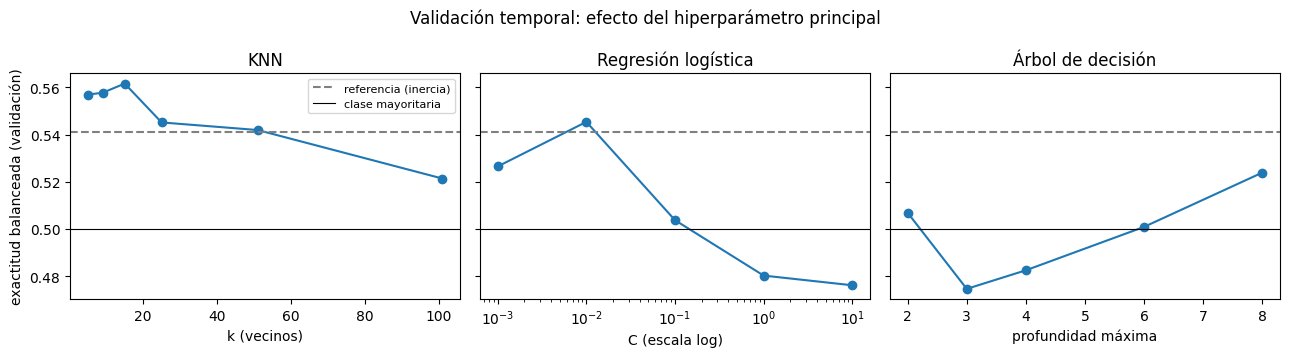

In [7]:
def curva(nombre, param):
    mejor = mejores.loc[mejores["modelo"] == nombre, "params"].iloc[0]
    otros = {k: v for k, v in mejor.items() if k != param}
    sub = resultados[resultados["modelo"] == nombre]
    sub = sub[sub["params"].map(lambda p: all(p[k] == v for k, v in otros.items()))]
    return sub.assign(valor=sub["params"].map(lambda p: p[param]))[["valor", "exactitud_balanceada"]]

fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (nombre, param, etiqueta) in zip(ejes, [("knn", "n_neighbors", "k (vecinos)"),
                                               ("logistica", "C", "C (escala log)"),
                                               ("arbol", "max_depth", "profundidad máxima")]):
    c = curva(nombre, param)
    ax.plot(c["valor"].astype(float), c["exactitud_balanceada"], marker="o")
    ax.axhline(referencias_val.loc["Referencia (inercia)", ("exactitud balanceada", "promedio")],
               color="grey", linestyle="--", label="referencia (inercia)")
    ax.axhline(0.5, color="black", linewidth=0.8, label="clase mayoritaria")
    if nombre == "logistica":
        ax.set_xscale("log")
    ax.set_title(train.NOMBRES[nombre]); ax.set_xlabel(etiqueta)
ejes[0].set_ylabel("exactitud balanceada (validación)")
ejes[0].legend(fontsize=8)
fig.suptitle("Validación temporal: efecto del hiperparámetro principal")
fig.tight_layout()
fig.savefig(FIGURES / "05_validacion_hiperparametros.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura de la validación:**

- **KNN con k = 15** (votación uniforme, escalado estándar) obtiene la mejor exactitud balanceada promedio: **0,562**, frente a **0,541** de la referencia y 0,500 de la clase mayoritaria. Por eso es el **modelo elegido**. La diferencia con la referencia (0,02) es menor que la variación entre cortes (desvío 0,055), así que la validación **no muestra una mejora clara** sobre la inercia.
- En KNN, los valores chicos de k (5 a 15) dan resultados parecidos y el mejor es k = 15. Con muchos vecinos (51, 101) empeora: la votación se parece cada vez más a la proporción general de contracciones y el modelo pierde capacidad de distinguir casos.
- La **regresión logística** necesita regularización fuerte (C = 0,01): con C grande empeora, lo que sugiere que con poca regularización se ajusta a relaciones propias del período de entrenamiento.
- **Árbol, Random Forest y Gradient Boosting** quedan cerca de 0,52: en varios cortes predicen casi todo de una misma clase (exactitud balanceada 0,50). El árbol elegido tiene profundidad 8: limitar la profundidad no evitó que aprendiera reglas que no se sostienen en el año siguiente.
- En todos los modelos el desempeño cambia mucho entre cortes. Los cambios de ciclo (salida de la recesión en 2021, nueva caída en 2023-2024) son justamente lo que cuesta anticipar.

## 4. Evaluación final en 2025-2026 (una sola vez)

Cada algoritmo se entrena **una vez** con todo el entrenamiento y con la configuración elegida en la validación, y se evalúa **una vez** en las 272 predicciones de 2025-2026. Estos resultados no se usan para cambiar ningún hiperparámetro. El modelo elegido es el de mejor validación (sección 3); los demás se muestran como comparación sobre las mismas observaciones.

In [8]:
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score, recall_score,
                             roc_auc_score, classification_report)

def metricas(y, pred, prob=None):
    return {"exactitud": accuracy_score(y, pred),
            "exactitud balanceada": balanced_accuracy_score(y, pred),
            "precisión": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "AUC": roc_auc_score(y, prob) if prob is not None else np.nan}

modelos_finales, predicciones, filas = {}, {}, []
for _, fila in mejores.iterrows():
    modelo = train.entrenar(fila["modelo"], fila["params"], entrenamiento)
    prob = modelo.predict_proba(X_eval)[:, 1]
    pred = (prob >= train.UMBRAL).astype(int)
    modelos_finales[fila["modelo"]], predicciones[fila["modelo"]] = modelo, (pred, prob)
    filas.append({"modelo": train.NOMBRES[fila["modelo"]], **metricas(y_eval, pred, prob)})

dummy = DummyClassifier(strategy="most_frequent").fit(X_ent, y_ent)
filas.append({"modelo": "Referencia (inercia)", **metricas(y_eval, evaluacion["contraccion_hoy"])})
filas.append({"modelo": "Clase mayoritaria", **metricas(y_eval, dummy.predict(X_eval))})
resultados_eval = pd.DataFrame(filas).set_index("modelo")
ELEGIDO = mejores.iloc[0]["modelo"]
print("Modelo elegido por validación:", train.NOMBRES[ELEGIDO], mejores.iloc[0]["params"])
print("Proporción de contracción en 2025-2026:", round(y_eval.mean(), 3))
resultados_eval.round(3)

Modelo elegido por validación: KNN {'n_neighbors': 15, 'weights': 'uniform', 'escalado': 'estandar'}
Proporción de contracción en 2025-2026: 0.574


,exactitud,exactitud balanceada,precisión,recall,F1,AUC
modelo,,,,,,
KNN,0.555,0.556,0.628,0.551,0.587,0.572
Regresión logística,0.548,0.602,0.923,0.231,0.369,0.664
Random Forest,0.382,0.445,0.167,0.019,0.034,0.486
Árbol de decisión,0.404,0.469,0.312,0.032,0.058,0.536
Gradient Boosting,0.555,0.569,0.655,0.474,0.550,0.604
Referencia (inercia),0.551,0.555,0.629,0.532,0.576,NaN
Clase mayoritaria,0.574,0.500,0.574,1.000,0.729,NaN


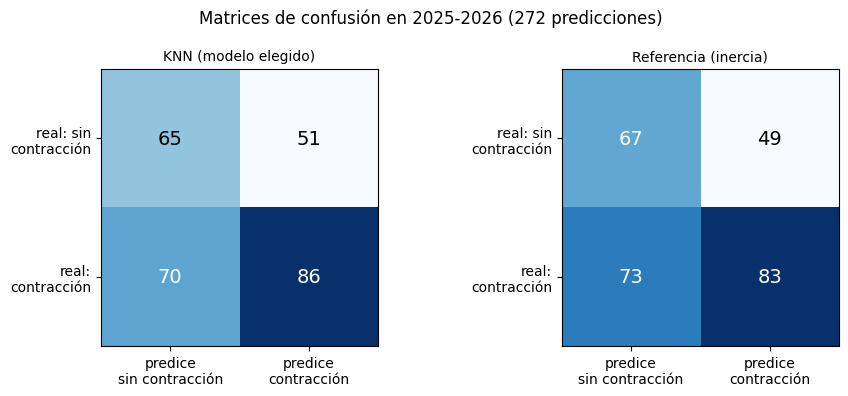

Modelo elegido: VP=86, FP=51, FN=70, VN=65
                 precision    recall  f1-score   support

sin contracción       0.48      0.56      0.52       116
    contracción       0.63      0.55      0.59       156

       accuracy                           0.56       272
      macro avg       0.55      0.56      0.55       272
   weighted avg       0.57      0.56      0.56       272



In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(9.5, 4))
for ax, (titulo, pred) in zip(ejes, [(f"{train.NOMBRES[ELEGIDO]} (modelo elegido)", predicciones[ELEGIDO][0]),
                                    ("Referencia (inercia)", evaluacion["contraccion_hoy"])]):
    mc = confusion_matrix(y_eval, pred, labels=[0, 1])
    ax.imshow(mc, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, mc[i, j], ha="center", va="center", fontsize=14,
                    color="white" if mc[i, j] > (mc.min() + mc.max()) / 2 else "black")
    ax.set_xticks([0, 1], ["predice\nsin contracción", "predice\ncontracción"])
    ax.set_yticks([0, 1], ["real: sin\ncontracción", "real:\ncontracción"])
    ax.set_title(titulo, fontsize=10)
fig.suptitle("Matrices de confusión en 2025-2026 (272 predicciones)")
fig.tight_layout()
fig.savefig(FIGURES / "06_matriz_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

mc = confusion_matrix(y_eval, predicciones[ELEGIDO][0], labels=[0, 1])
vn, fp, fn, vp = mc.ravel()
print(f"Modelo elegido: VP={vp}, FP={fp}, FN={fn}, VN={vn}")
print(classification_report(y_eval, predicciones[ELEGIDO][0], target_names=["sin contracción", "contracción"], zero_division=0))

**Lectura de la evaluación final (clase positiva = contracción):**

- El **KNN elegido** obtiene en 2025-2026 una exactitud balanceada de **0,556**, prácticamente igual a la de la **referencia (0,555)**. De las **156** contracciones reales detectó **86** (recall 0,551) y emitió **137** alertas, de las cuales **51** fueron falsas alarmas (precisión 0,628). Quedaron **70** contracciones sin anticipar. La referencia detectó 83 (recall 0,532) con una precisión casi igual (0,629).
- La **clase mayoritaria** ("siempre contracción") tiene la mayor exactitud (0,574) y el mayor F1 (0,729), pero no anticipa nada: exactitud balanceada 0,500. Esto confirma por qué no se usó F1 para elegir.
- La **regresión logística** obtuvo en este período la mayor exactitud balanceada (0,602) y el mayor AUC (0,664), pero con un recall muy bajo (0,231): da pocas alertas y casi todas aciertan (precisión 0,923). **No se cambia el modelo elegido** a partir de este resultado, porque eso sería elegir con el conjunto de prueba. Queda como hipótesis para revisar con más datos.
- **Random Forest y el árbol** prácticamente no predijeron contracciones en 2025-2026 (recall 0,02 y 0,03). Una explicación posible, no comprobada, es que aprendieron umbrales sobre variables nominales (por ejemplo, la variación del tipo de cambio, que es la primera pregunta del árbol) que dejaron de tener el mismo significado cuando bajó la inflación en 2025.
- Con la evidencia disponible, **el modelo elegido no superó de forma clara a la referencia de inercia** en este período. Es un resultado limitado pero informativo: sugiere que, con estas variables y 3 meses de anticipación, la señal disponible podría ser débil.

### ¿Dónde acierta y dónde se equivoca?

Exactitud balanceada por trimestre del mes predicho y por división, para el modelo elegido y la referencia:

In [10]:
detalle = evaluacion[["fecha", "codigo_division", "division", "objetivo", "contraccion_hoy"]].copy()
detalle["pred"] = predicciones[ELEGIDO][0]
detalle["prob"] = predicciones[ELEGIDO][1]
detalle["mes_predicho"] = detalle["fecha"] + pd.DateOffset(months=5)
detalle["trimestre_predicho"] = detalle["mes_predicho"].dt.to_period("Q").astype(str)

def resumen(g):
    return pd.Series({"filas": len(g), "proporción real de contracción": g["objetivo"].mean(),
                      "acierto modelo": (g["pred"] == g["objetivo"]).mean(),
                      "acierto referencia": (g["contraccion_hoy"] == g["objetivo"]).mean()})

por_trimestre = detalle.groupby("trimestre_predicho").apply(resumen, include_groups=False)
por_trimestre.round(2)

,filas,proporción real de contracción,acierto modelo,acierto referencia
trimestre_predicho,,,,
2025Q2,48.0,0.10,0.60,0.56
2025Q3,48.0,0.60,0.40,0.50
2025Q4,48.0,0.73,0.38,0.35
2026Q1,48.0,0.65,0.58,0.60
2026Q2,48.0,0.69,0.71,0.67
2026Q3,32.0,0.72,0.72,0.66


In [11]:
por_division = detalle.groupby(["codigo_division", "division"]).apply(resumen, include_groups=False)
por_division.sort_values("acierto modelo").round(2)

,,filas,proporción real de contracción,acierto modelo,acierto referencia
codigo_division,division,,,,
23,"Refinación del petróleo, coque y combustible nuclear",17.0,0.06,0.41,0.76
27,Industrias metálicas básicas,17.0,0.53,0.41,0.35
28,Productos de metal,17.0,0.88,0.41,0.76
15,Alimentos y bebidas,17.0,0.59,0.47,0.41
16,Productos de tabaco,17.0,0.41,0.47,0.35
24,Sustancias y productos químicos,17.0,0.35,0.47,0.47
36-38,"Muebles y colchones, y otras industrias manufactureras",17.0,0.59,0.53,0.47
18-19,"Prendas de vestir, cuero y calzado",17.0,0.88,0.59,0.65
25,Productos de caucho y plástico,17.0,0.76,0.59,0.53


**Lectura de los errores:**

- En esta muestra, ni el modelo ni la referencia anticiparon el **cambio de ciclo de mediados de 2025**: la proporción de contracciones pasó del 10% (meses predichos del segundo trimestre de 2025) al 60-73% (tercer y cuarto trimestre). En esos dos trimestres el acierto del modelo cae a 0,38-0,40. Cuando la tendencia se estabiliza (meses predichos desde el segundo trimestre de 2026), ambos aciertan entre el 66% y el 72%.
- Por división, el modelo acierta más que la referencia en 10 de las 16, menos en 4 e igual en 2. Falla sobre todo en **Refinación del petróleo** (0,41 contra 0,76 de la referencia), una división casi siempre en crecimiento en este período, y en **Productos de metal** (0,41 contra 0,76). Son 17 predicciones por división, así que estas diferencias son muy inestables.

## 5. Interpretación del modelo

### ¿Qué variables usa más el modelo?

KNN no tiene coeficientes, así que se usa la **importancia por permutación**: se mezclan al azar los valores de una variable y se mide cuánto empeora la exactitud balanceada. Se calcula sobre 2025-2026 solo para **describir** el modelo ya elegido: no se cambia nada a partir de este resultado. Es una medida de asociación predictiva, no de causalidad.

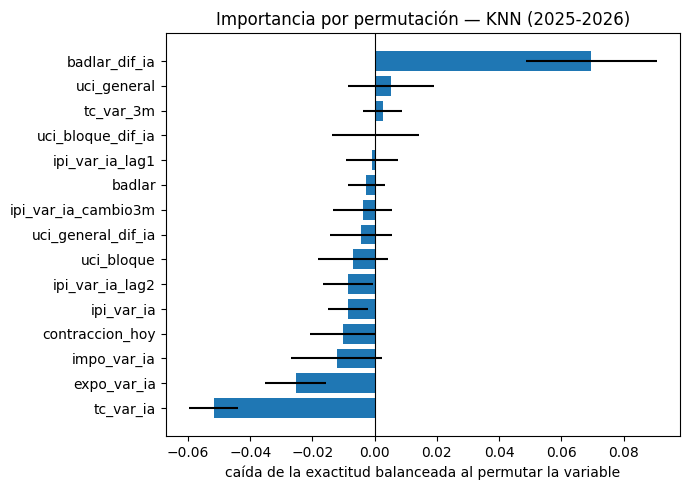

,importancia media,desvío
badlar_dif_ia,0.070,0.021
uci_general,0.005,0.014
tc_var_3m,0.003,0.006
uci_bloque_dif_ia,0.000,0.014
ipi_var_ia_lag1,-0.001,0.008
badlar,-0.003,0.006
ipi_var_ia_cambio3m,-0.004,0.010
uci_general_dif_ia,-0.004,0.010
uci_bloque,-0.007,0.011
ipi_var_ia_lag2,-0.009,0.008


In [12]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(modelos_finales[ELEGIDO], X_eval, y_eval, scoring="balanced_accuracy",
                             n_repeats=30, random_state=train.SEMILLA)
importancia = pd.DataFrame({"importancia media": imp.importances_mean, "desvío": imp.importances_std},
                           index=PREDICTORAS).sort_values("importancia media")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importancia.index, importancia["importancia media"], xerr=importancia["desvío"], color="tab:blue")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("caída de la exactitud balanceada al permutar la variable")
ax.set_title(f"Importancia por permutación — {train.NOMBRES[ELEGIDO]} (2025-2026)")
fig.tight_layout()
fig.savefig(FIGURES / "07_importancia_permutacion.png", dpi=150, bbox_inches="tight")
plt.show()
importancia.sort_values("importancia media", ascending=False).round(3)

### Regresión logística: dirección de cada variable

Aunque no es el modelo elegido, sus coeficientes muestran en qué **dirección** se asocia cada variable con la probabilidad de contracción. Están en la escala de las variables escaladas (robusto: mediana e IQR del entrenamiento), así que se pueden comparar entre sí. Un coeficiente positivo indica que valores más altos se asocian con **mayor** probabilidad predicha de contracción.

In [13]:
log = modelos_finales["logistica"]
coef = pd.Series(log.named_steps["modelo"].coef_[0], index=PREDICTORAS).sort_values()
print("Intercepto:", round(log.named_steps["modelo"].intercept_[0], 3))
coef.round(3).to_frame("coeficiente")

Intercepto: 0.014


,coeficiente
impo_var_ia,-0.249
ipi_var_ia,-0.198
uci_general_dif_ia,-0.164
uci_bloque_dif_ia,-0.160
uci_bloque,-0.029
expo_var_ia,-0.026
ipi_var_ia_lag2,-0.008
ipi_var_ia_cambio3m,-0.006
ipi_var_ia_lag1,0.000
badlar,0.030


## 6. Cómo produce una predicción cada modelo: un caso concreto

Se toma una fila de 2025-2026: **Maquinaria y equipo (división 29)**, dato de **diciembre de 2024**. La predicción se hace en febrero de 2025 y se refiere a **mayo de 2025** frente a mayo de 2024.

In [14]:
caso = evaluacion[(evaluacion["codigo_division"] == "29") & (evaluacion["fecha"] == "2024-12-01")]
print("Resultado real (objetivo):", int(caso["objetivo"].iloc[0]), "| contracción hoy:", int(caso["contraccion_hoy"].iloc[0]))
caso[PREDICTORAS].T.rename(columns=lambda c: "valor").round(3)

Resultado real (objetivo): 0 | contracción hoy: 0


,valor
ipi_var_ia,0.343
ipi_var_ia_lag1,0.079
ipi_var_ia_lag2,-0.080
ipi_var_ia_cambio3m,0.505
contraccion_hoy,0.000
uci_bloque,50.000
uci_bloque_dif_ia,-0.300
uci_general,62.300
uci_general_dif_ia,-4.100
tc_var_ia,0.590


In [15]:
# KNN: busca los 15 casos del entrenamiento más parecidos (en la escala estandarizada) y vota
knn = modelos_finales["knn"]
escalado = knn.named_steps["escalado"].transform(caso[PREDICTORAS])
dist, idx = knn.named_steps["modelo"].kneighbors(escalado)
vecinos = entrenamiento.iloc[idx[0]][["fecha", "division", "objetivo"]].assign(distancia=dist[0].round(2))
print(f"KNN: {int(vecinos['objetivo'].sum())} de {len(vecinos)} vecinos terminaron en contracción "
      f"-> probabilidad {vecinos['objetivo'].mean():.2f} -> clase {int(vecinos['objetivo'].mean() >= train.UMBRAL)}")
vecinos.assign(fecha=vecinos["fecha"].dt.strftime("%m/%Y"))

KNN: 4 de 15 vecinos terminaron en contracción -> probabilidad 0.27 -> clase 0


,fecha,division,objetivo,distancia
1464,09/2020,Maquinaria y equipo,0.0,3.77
1976,09/2020,"Muebles y colchones, y otras industrias manufactureras",1.0,3.89
952,09/2020,Productos de caucho y plástico,0.0,3.89
1592,09/2020,"Otros equipos, aparatos e instrumentos",0.0,3.94
568,09/2020,"Madera, papel, edición e impresión",1.0,4.02
56,09/2020,Alimentos y bebidas,0.0,4.04
1720,09/2020,"Vehículos automotores, carrocerías, remolques y autopartes",1.0,4.07
1808,05/2017,Otro equipo de transporte,0.0,4.11
1463,08/2020,Maquinaria y equipo,0.0,4.15
1296,05/2017,Productos de metal,0.0,4.16


In [16]:
# Regresión logística: combina las variables escaladas con los coeficientes y aplica la sigmoide
p_log = log.predict_proba(caso[PREDICTORAS])[0, 1]
z = log.named_steps["modelo"].decision_function(log.named_steps["escalado"].transform(caso[PREDICTORAS]))[0]
print(f"Regresión logística: z = {z:.3f} -> probabilidad = 1 / (1 + e^-z) = {p_log:.3f}")
for u in (0.5, 0.35):
    print(f"  con umbral {u}: clase {int(p_log >= u)}")

Regresión logística: z = -1.674 -> probabilidad = 1 / (1 + e^-z) = 0.158
  con umbral 0.5: clase 0
  con umbral 0.35: clase 0


In [17]:
# Árbol de decisión: recorrido de las condiciones hasta una hoja
arbol = modelos_finales["arbol"].named_steps["modelo"]
nodos = arbol.decision_path(caso[PREDICTORAS]).indices
hoja = arbol.apply(caso[PREDICTORAS])[0]
for n in nodos:
    if n == hoja:
        valores = arbol.tree_.value[n][0]
        print(f"Hoja {n}: proporción ponderada de contracción = {valores[1] / valores.sum():.2f} "
              f"-> clase {arbol.classes_[valores.argmax()]:.0f}")
    else:
        var, umbral_n = PREDICTORAS[arbol.tree_.feature[n]], arbol.tree_.threshold[n]
        valor = caso[var].iloc[0]
        print(f"Nodo {n}: ¿{var} <= {umbral_n:.3f}?  valor = {valor:.3f} -> {'sí' if valor <= umbral_n else 'no'}")

Nodo 0: ¿tc_var_ia <= 0.463?  valor = 0.590 -> no
Nodo 70: ¿tc_var_3m <= 0.208?  valor = 0.061 -> sí
Nodo 71: ¿ipi_var_ia <= -0.035?  valor = 0.343 -> no
Nodo 97: ¿expo_var_ia <= 0.167?  valor = 0.329 -> no
Hoja 117: proporción ponderada de contracción = 0.14 -> clase 0


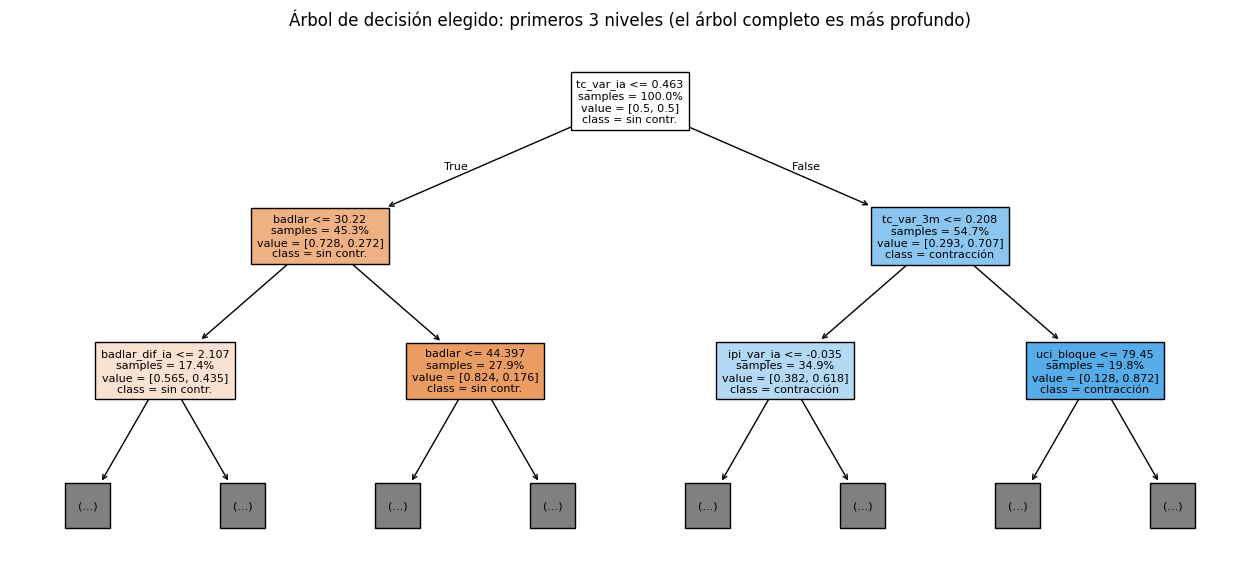

In [18]:
from sklearn.tree import plot_tree
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(arbol, feature_names=PREDICTORAS, class_names=["sin contr.", "contracción"], max_depth=2,
          filled=True, impurity=False, proportion=True, fontsize=8, ax=ax)
ax.set_title("Árbol de decisión elegido: primeros 3 niveles (el árbol completo es más profundo)")
fig.savefig(FIGURES / "08_arbol_primeros_niveles.png", dpi=150, bbox_inches="tight")
plt.show()

**Cómo llegó cada modelo a su predicción para este caso** (resultado real: sin contracción en mayo de 2025):

- **KNN:** busca, en la escala estandarizada con media y desvío del entrenamiento, los 15 casos del entrenamiento más parecidos. 11 de los 15 no terminaron en contracción, así que la probabilidad estimada es 4/15 = 0,27, menor que el umbral 0,5: predice **sin contracción** (correcto). La mayoría de los vecinos son de **septiembre de 2020**, de distintas divisiones: como las variables macroeconómicas son iguales para todas las divisiones de un mes, probablemente pesan mucho en la distancia, y el modelo parecería buscar sobre todo **meses parecidos**. En este caso, la caída fuerte de la BADLAR (−88 puntos) se parece a la salida de la pandemia.
- **Regresión logística:** combina las variables escaladas con sus coeficientes (z = −1,67) y la sigmoide da una probabilidad de **0,16**. Con umbral 0,5 predice sin contracción, y también con un umbral más bajo como 0,35.
- **Árbol de decisión:** pregunta primero por la variación interanual del tipo de cambio (0,59, mayor que 0,463), luego por la de 3 meses (0,061, menor que 0,208), luego por la variación interanual del IPI de la división (+34%, mayor que −3,5%) y por las exportaciones. Llega a una hoja donde solo el 14% (ponderado) fue contracción: predice **sin contracción**.
- La referencia también acierta (la división no estaba en contracción en diciembre de 2024).

## 7. Uso del modelo para predecir casos nuevos

**Modelo de uso.** Para predecir hacia adelante, el modelo elegido (con los mismos hiperparámetros) se reentrena con **todas las filas cuyo resultado ya se conoce** (entrenamiento + evaluación). Se guarda en `models/modelo_final.joblib`, junto con el escalado aprendido, y se usa con `contraccion_industrial/modeling/predict.py`.

**Casos nuevos reales.** Las 80 filas *pendientes* (datos de abril a agosto 2026) son predicciones reales: su resultado todavía no se publicó. Cuando el INDEC publique el IPI de esos meses, se podrá comprobar si el modelo acertó.

In [19]:
observadas = pd.concat([entrenamiento, evaluacion])
modelo_uso = train.entrenar(ELEGIDO, mejores.iloc[0]["params"], observadas)
ruta = train.guardar(modelo_uso, "modelo_final.joblib")
print("Modelo de uso:", train.NOMBRES[ELEGIDO], mejores.iloc[0]["params"])
print("Entrenado con", len(observadas), "filas; guardado en", ruta.relative_to(PARCIAL))

nuevas = predecir(modelo_uso, pendientes)
nuevas[["fecha", "mes_decision", "mes_predicho", "codigo_division", "division", "contraccion_hoy",
        "prob_contraccion", "prediccion"]].to_csv(PARCIAL / "models" / "predicciones_pendientes.csv", index=False)
ultimo = nuevas[nuevas["fecha"] == nuevas["fecha"].max()]
print(f"\nPredicción hecha en {ultimo['mes_decision'].iloc[0]:%m/%Y} (dato de {ultimo['fecha'].iloc[0]:%m/%Y}) "
      f"para {ultimo['mes_predicho'].iloc[0]:%m/%Y}:")
ultimo[["codigo_division", "division", "contraccion_hoy", "prob_contraccion", "prediccion"]] \
    .sort_values("prob_contraccion", ascending=False).round(2)

Modelo de uso: KNN {'n_neighbors': 15, 'weights': 'uniform', 'escalado': 'estandar'}
Entrenado con 1648 filas; guardado en models/modelo_final.joblib

Predicción hecha en 10/2026 (dato de 08/2026) para 01/2027:


,codigo_division,division,contraccion_hoy,prob_contraccion,prediccion
1663,30-33,"Otros equipos, aparatos e instrumentos",1.0,0.93,1
1535,29,Maquinaria y equipo,1.0,0.80,1
255,16,Productos de tabaco,1.0,0.73,1
1023,25,Productos de caucho y plástico,1.0,0.73,1
1407,28,Productos de metal,1.0,0.73,1
1791,34,"Vehículos automotores, carrocerías, remolques y autopartes",1.0,0.73,1
127,15,Alimentos y bebidas,1.0,0.67,1
2047,36-38,"Muebles y colchones, y otras industrias manufactureras",1.0,0.67,1
511,18-19,"Prendas de vestir, cuero y calzado",1.0,0.60,1
1151,26,Productos minerales no metálicos,1.0,0.60,1


**Un caso nuevo cargado a mano.** Para mostrar el formato de entrada, se arma una fila sintética: una división hipotética que hoy cae 8% interanual, con la capacidad instalada en baja y una devaluación fuerte. Los valores son inventados (dentro de los rangos observados) y **no sirven para evaluar** el modelo, solo para mostrar cómo se usa.

In [20]:
caso_nuevo = pd.DataFrame([{
    "ipi_var_ia": -0.08, "ipi_var_ia_lag1": -0.05, "ipi_var_ia_lag2": -0.03, "ipi_var_ia_cambio3m": -0.06,
    "contraccion_hoy": 1, "uci_bloque": 55.0, "uci_bloque_dif_ia": -4.0, "uci_general": 60.0,
    "uci_general_dif_ia": -3.0, "tc_var_ia": 1.20, "tc_var_3m": 0.25, "badlar": 45.0,
    "badlar_dif_ia": 10.0, "expo_var_ia": 0.02, "impo_var_ia": -0.15}])
predecir(modelo_uso, caso_nuevo)[["prob_contraccion", "prediccion"]]

,prob_contraccion,prediccion
0,0.8,1


## 8. Conclusiones

**Sobre el problema planteado** (con la evidencia de este trabajo). El objetivo era anticipar, con 3 meses de horizonte desde el momento de la decisión, qué divisiones van a estar en contracción interanual. Con los datos y las variables disponibles, el modelo elegido por validación (**KNN, k = 15**) alcanza en 2025-2026 una exactitud balanceada de **0,556** y detecta el **55%** de las contracciones, con un **63%** de alertas correctas. Es **prácticamente el mismo desempeño que la referencia** de inercia (0,555). Con esta evidencia **no es posible afirmar** que el modelo anticipe mejor que suponer que cada división seguirá como en el último dato publicado.

**Qué sí aporta el trabajo:**
- Un procedimiento de evaluación **sin fuga de información**: cada variable se usa solo si estaba publicada en *t+2*, el entrenamiento solo incluye resultados ya conocidos, los hiperparámetros se eligen con validación temporal y la prueba se hace una sola vez.
- La comparación sugiere **dónde estaría la dificultad**: en los cambios de ciclo (2021, mediados de 2025), que en esta muestra ningún modelo anticipó.
- Un modelo listo para usar (`models/modelo_final.joblib`) y **predicciones reales pendientes**. Con el último dato publicado (agosto 2026), el modelo estima contracción en enero de 2027 para 12 de las 16 divisiones. Se podrán verificar cuando el INDEC publique el IPI de esos meses.

**Hipótesis (no comprobadas):**
- Es posible que las variables macroeconómicas **nominales** (tipo de cambio, BADLAR) cambien de significado cuando cambia la inflación. Eso podría explicar por qué los árboles fallaron en 2025-2026 y por qué la variación del tipo de cambio empeora al KNN en ese período (importancia por permutación negativa).
- La regresión logística, más conservadora, podría ser preferible si se priorizan alertas con alta precisión. Habría que comprobarlo con más períodos de validación.

**Limitaciones:**
- Pocos ciclos económicos en 2017-2026; las variables macro tienen un solo valor por mes para las 16 divisiones.
- Series revisadas (no las versiones publicadas en cada momento).
- Sin ajuste por precios ni ajuste estacional.
- Correspondencias aproximadas de capacidad instalada para algunas divisiones.
- Umbral fijo en 0,5.
- 17 predicciones por división en la evaluación final.

**Trabajo futuro:**
- Deflactar las variables nominales por un índice de precios.
- Usar series desestacionalizadas.
- Incorporar la división como variable categórica.
- Elegir el umbral con validación según el costo de cada error.
- **Reentrenar el modelo** a medida que se publiquen nuevos meses y verificar las predicciones pendientes.